# Mejora acotada de un prompt YAML

[English](prompt-search.ipynb) | Español | [Caso](README.es.md) | [Definiciones y modelamiento](modeling.es.md)

**Estado: preparada, sin ejecutar con OpenAI.** Esta notebook modifica el prompt de política de
un asistente de deudas sintéticas. Modelo, runtime, optimizador y evaluador permanecen fijos.
No se afirma mejora recursiva ni un resultado real. Ambos idiomas usan la misma implementación
y pueden mostrar una sola ejecución.

El asistente busca la mayor deuda viable entre 200, 300 y 600, en uno o dos pagos y con
consentimiento explícito. Genera una siguiente respuesta para cada historial fijo.


## 1. Entorno local

Seguir la [preparación local](modeling.es.md#preparación-local), instalar `requirements.txt`,
elegir el kernel y completar `.env` a partir de [.env.example](.env.example). No poner la clave
en una celda. Por defecto solo se leen archivos, sin instalaciones ni llamadas automáticas.


In [ ]:
LANGUAGE = 'es'
from pathlib import Path
import importlib.util
import json
import sys
import difflib
from html import escape
import yaml
from dotenv import load_dotenv
from IPython.display import Markdown, HTML, display

relative = Path("research/proposals/case-0003-debt-negotiation")
CASE = next((base / relative for base in [Path.cwd(), *Path.cwd().parents]
             if (base / relative / "prompt_search.py").is_file()), None)
if CASE is None:
    raise RuntimeError("Open this notebook inside the thinking-harness checkout")
spec = importlib.util.spec_from_file_location("case3_search", CASE / "prompt_search.py")
search = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = search
spec.loader.exec_module(search)
load_dotenv(CASE / ".env", override=False)  # Never display credentials.

def text(en, es):
    return es if LANGUAGE == "es" else en

def block(value):
    display(HTML("<pre>" + escape(str(value)) + "</pre>"))

cases = search.load_cases()
seed = yaml.safe_load((CASE / "prompt.yaml").read_text())
search.get_prompt(seed)
settings = yaml.safe_load((CASE / "config.yaml").read_text())
config = search.Config(**settings)
config.validate()
print(text("Local inputs loaded. No API calls.", "Entradas locales cargadas. Sin llamadas a la API."))

## 2. Política y golden set

[prompt.yaml](prompt.yaml) es la política modificable; [golden-set.yaml](golden-set.yaml) contiene
18 ejemplos sintéticos. [objective.md](objective.md) fija las reglas. El optimizador solo ve
desarrollo. Validación selecciona candidatos; la prueba final queda fuera del bucle.

Una capacidad de 170 permite B en dos pagos de 150. C en dos pagos de 300 no es viable.
La brecha `cuota - capacidad` es una característica derivada. Definir entradas y salidas es
modelamiento del sistema. El runtime no entrena pesos ni exige respuestas textualmente iguales.


In [ ]:
print(text("Initial YAML policy", "Política YAML inicial"))
block((CASE / "prompt.yaml").read_text())
print(text("Synthetic partitions", "Particiones sintéticas"))
block({split: sum(c["split"] == split for c in cases)
       for split in ("development", "validation", "test")})
example = next(c for c in cases if c["id"] == "development-limited")
print(text("One golden example (labels are evaluator-only)",
           "Ejemplo del golden set (etiquetas exclusivas del evaluador)"))
block(yaml.safe_dump(example, sort_keys=False, allow_unicode=True))
print(text("Actual negotiator input", "Entrada efectiva del negociador"))
block(yaml.safe_dump(search.visible(example), sort_keys=False, allow_unicode=True))

## 3. Protocolo y presupuesto

Una respuesta es exitosa si coincide con la decisión esperada, cumple las reglas y un juez LLM
fijo confirma consistencia, pertinencia y claridad. El puntaje es la fracción de respuestas
exitosas. Solo se seleccionan candidatos sin incumplimientos y con ganancia mínima `min_gain`.
Es búsqueda discreta, no descenso de gradiente. Falta calibrar el juez.

`p000` es la semilla genérica. `p001` es el baseline generado una vez desde el objetivo y los
ejemplos de desarrollo. Las versiones posteriores cambian solo el campo `prompt` del YAML.
Si el baseline alcanza la meta, no se itera. La semilla no es el baseline de comparación final.

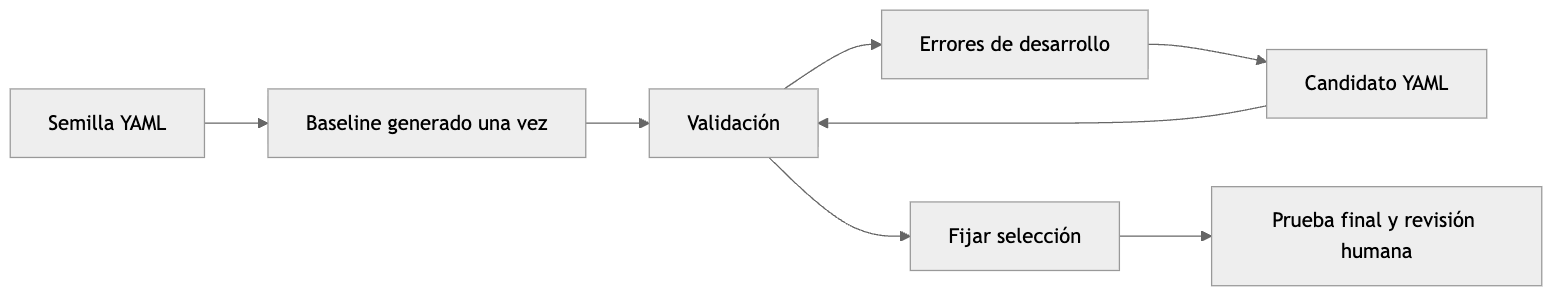

```mermaid
flowchart LR
    S[Semilla YAML] --> B[Baseline generado una vez]
    B --> V[Validación]
    V --> D[Errores de desarrollo]
    D --> C[Candidato YAML]
    C --> V
    V --> F[Fijar selección]
    F --> T[Prueba final y revisión humana]
```

La vista previa incluida se genera desde el código Mermaid mostrado. Regenerarla al editar el diagrama.
El límite común incluye todos los roles y la prueba final. Es una estimación, no un límite
de facturación del proveedor. Revisar [config.yaml](config.yaml); hay dos interruptores explícitos.


In [ ]:
RUN_LIVE = False
REPLAY_REPORT = ""  # Example after a real run: runs/<run-id>/report.json

# Both this switch and config.yaml allow_live must be true for a charged run.
print(text("Configured bounds", "Límites configurados"))
block(settings)
counts = {s: sum(c["split"] == s for c in cases) for s in ("development", "validation", "test")}
upper_calls = (1 + 2 * counts["validation"] * config.evaluation_repeats
    + config.max_iterations * (2 * counts["development"] * config.evaluation_repeats
        + config.candidates_per_iteration * (1 + 2 * counts["validation"] * config.evaluation_repeats))
    + 4 * counts["test"] * config.evaluation_repeats)
print(text("Maximum scheduled calls before early stops:", "Máximo de llamadas antes de paradas anticipadas:"), upper_calls)
print(text("The common budget may stop the run before final testing.",
           "El presupuesto común puede detener la ejecución antes de la prueba final."))

## 4. Ejecutar una vez o leer un reporte

Mantener desactivado el modo real hasta completar la clave. Para revisar una ejecución, usar
solo `REPLAY_REPORT`. Repetir esta celda en modo real genera otro experimento con costo.
La ejecución guarda evidencia por etapa; las celdas siguientes la presentan paso a paso.


In [ ]:
report = None
if RUN_LIVE and REPLAY_REPORT:
    raise ValueError("Choose live execution OR replay, not both")
if RUN_LIVE:
    # Fresh charged run each time this cell executes. No automatic retries.
    report = search.run_search(config)
    report_path = Path(report["evidence_dir"]) / "report.json"
    print(text("Replay path:", "Ruta para volver a mostrar el reporte:"), report_path.relative_to(CASE))
elif REPLAY_REPORT:
    report_path = (CASE / REPLAY_REPORT).resolve()
    if not report_path.is_relative_to(CASE.resolve()):
        raise ValueError("Use a report inside the case folder")
    report = json.loads(report_path.read_text())
    if report.get("protocol") != search.PROTOCOL or report.get("mode") != "live":
        raise ValueError("Expected a live report from this protocol, not a test double")
    # Replay uses saved evidence, never current settings or a new API call.
    print(text("Replaying saved evidence. No API calls.", "Lectura de evidencia guardada. Sin llamadas a la API."))
else:
    print(text("NOT RUN. Add the local API key and review the configuration before enabling live mode.",
               "SIN EJECUTAR. Completar la clave local y revisar la configuración antes de activar el modo real."))

## 5. Cada versión YAML y su decisión

Se muestran semilla, baseline y todos los candidatos, incluidos duplicados y descartados.
Un candidato pendiente no tiene una evaluación completa. Las diferencias muestran qué cambió.


In [ ]:
if report is None:
    print(text("Prompt versions and decisions will appear after a real run.",
               "Las versiones y decisiones aparecerán después de una ejecución real."))
else:
    # Prompt contents are shown as escaped text, not executable notebook content.
    version_map = {v["id"]: v for v in report["versions"]}
    for version in report["versions"]:
        display(Markdown("### " + version["id"] + " | " + version["stage"]))
        print(text("Parent:", "Versión padre:"), version["parent"])
        saved = report_path.parent / version["path"]
        actual_hash = search.hashlib.sha256(saved.read_bytes()).hexdigest()
        if actual_hash != version["sha256"]:
            raise ValueError("Saved YAML hash differs from the run manifest")
        block(saved.read_text())
        parent = version_map.get(version["parent"])
        if parent:
            diff = difflib.unified_diff(parent["prompt"].splitlines(), version["prompt"].splitlines(),
                                        fromfile=parent["id"], tofile=version["id"], lineterm="")
            block("\n".join(diff) or text("No content change", "Sin cambio de contenido"))
        if version["id"] == report.get("initial_version"):
            result = report.get("initial_validation")
            block({"baseline_validation": None if result is None else
                   {k: result[k] for k in ("score", "violations")}})
        event = next((e for e in report["events"] if e.get("version") == version["id"]), None)
        if event:
            block({k: event[k] for k in ("iteration", "candidate", "status", "selected")})
            if "validation" in event:
                block({k: event["validation"][k] for k in ("score", "violations")})
        print(text("Selected at end:", "Seleccionada al terminar:"),
              version["id"] == report.get("selected_version"))

## 6. Errores y respuestas

Revisar errores de desarrollo, respuestas de validación y comparación final. Las referencias
son ejemplos, no una redacción obligatoria. Las respuestas conservan su idioma original en ambas notebooks.


In [ ]:
if report is not None:
    def show_evaluation(label, result):
        display(Markdown("### " + label))
        if result is None:
            print(text("Incomplete or not reached", "Incompleto o no alcanzado"))
            return
        block({k: result[k] for k in ("score", "violations")})
        # Show every reply and judge rationale, not only the aggregate score.
        for row in result["rows"]:
            block({"case": row["id"], "repeat": row["repeat"], "success": row["success"],
                   "history": row["context"]["history"], "reply": row["reply"],
                   "checks": row["checks"], "judge": row["judge"]})

    show_evaluation(text("Baseline validation", "Validación del baseline"), report.get("initial_validation"))
    for event in report["events"]:
        if "development" in event:
            show_evaluation(text("Development feedback, round ", "Errores de desarrollo, ronda ")
                            + str(event["iteration"]), event["development"])
        elif "validation" in event:
            show_evaluation(text("Candidate validation ", "Validación del candidato ")
                            + event["version"], event["validation"])
    show_evaluation(text("Final test: baseline", "Prueba final: baseline"), report.get("final_initial"))
    show_evaluation(text("Final test: selected", "Prueba final: seleccionada"), report.get("final_selected"))

## 7. Resultado y revisión

Reportar parada, consumo, versiones y comparación final sin inferir significancia de un conjunto
sintético pequeño. La prueba final nunca retroalimenta al optimizador.


In [ ]:
if report is not None:
    block({"mode": report["mode"], "protocol": report["protocol"],
           "initial_version": report.get("initial_version"),
           "selected_version": report.get("selected_version"),
           "stop_reason": report["stop_reason"], "final_complete": report["final_complete"],
           "usage": report.get("usage")})
    if report["final_complete"]:
        delta = report["final_selected"]["score"] - report["final_initial"]["score"]
        print(text("Observed final score difference:", "Diferencia observada del puntaje final:"), delta)
        print(text("This small synthetic comparison does not establish statistical or real-world improvement.",
                   "Esta comparación sintética pequeña no demuestra mejora estadística ni efectividad real."))
    else:
        print(text("Final comparison incomplete; do not claim improvement.",
                   "Comparación final incompleta; no afirmar una mejora."))
    print(text("Saved configuration and source hashes", "Configuración y hashes de la ejecución"))
    block({"config": report["config"], "source_hashes": report["source_hashes"],
           "git_commit": report["git_commit"]})

## Siguiente paso

La ejecución real está pendiente. Tras revisar la prueba local se publicarán evidencia depurada
y salidas de ambos idiomas a partir de esa misma ejecución. No publicar `.env` ni registros sin revisar.
Volver al [modelamiento](modeling.es.md), al [caso](README.es.md) o a la [notebook en inglés](prompt-search.ipynb).
